# Model Comparison - Credit Card Fraud

We train the 5 models again (same steps as the classification notebook), keep their predictions, and compare them in one table.

Main metric is **recall** (how many real frauds we catch), together with precision and F1.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

data = pd.read_csv('../Data/creditcard_clean.csv')

x = data.drop(columns=['Class', 'Hour'], errors='ignore')
y = data['Class']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

# balance the training data only
train = x_train.copy()
train['Class'] = y_train
class_1 = train[train['Class'] == 1]
class_0 = train[train['Class'] == 0].sample(len(class_1), random_state=42)
train_bal = pd.concat([class_0, class_1])
x_bal = train_bal.drop('Class', axis=1)
y_bal = train_bal['Class']

print(y_bal.value_counts())

Class
0    378
1    378
Name: count, dtype: int64


## Train the models

In [4]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_bal, y_bal)
pred_knn = knn.predict(x_test)

In [5]:
lr = LogisticRegression(max_iter=1000)
lr.fit(x_bal, y_bal)
pred_lr = lr.predict(x_test)

In [6]:
nb = GaussianNB()
nb.fit(x_bal, y_bal)
pred_nb = nb.predict(x_test)

In [7]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_bal, y_bal)
pred_dt = dt.predict(x_test)

In [8]:
svm = SVC()
svm.fit(x_bal, y_bal)
pred_svm = svm.predict(x_test)

## Comparison table

In [9]:
preds = {
    'KNN': pred_knn,
    'Logistic Regression': pred_lr,
    'Naive Bayes': pred_nb,
    'Decision Tree': pred_dt,
    'SVM': pred_svm,
}

results = pd.DataFrame({
    'Accuracy':  [accuracy_score(y_test, p) for p in preds.values()],
    'Precision': [precision_score(y_test, p) for p in preds.values()],
    'Recall':    [recall_score(y_test, p) for p in preds.values()],
    'F1':        [f1_score(y_test, p) for p in preds.values()],
}, index=preds.keys())

results.round(4)

,Accuracy,Precision,Recall,F1
KNN,0.9763,0.0573,0.8526,0.1074
Logistic Regression,0.9724,0.0507,0.8737,0.0959
Naive Bayes,0.9690,0.0423,0.8105,0.0805
Decision Tree,0.8965,0.0149,0.9368,0.0294
SVM,0.9864,0.0958,0.8421,0.1720


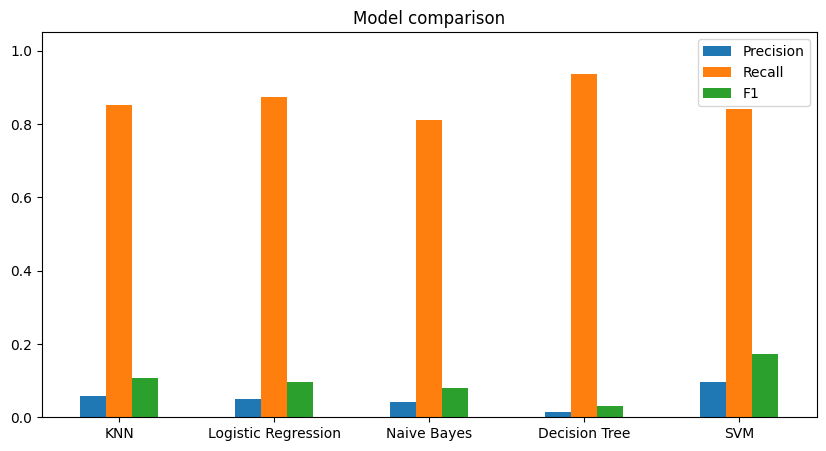

In [10]:
results[['Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(10, 5))
plt.title('Model comparison')
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.show()

## Best model
We pick the model with the highest F1 (a balance of precision and recall). If catching every fraud matters more, pick the highest recall instead.

In [11]:
best = results['F1'].idxmax()
print('Best model:', best)
print(results.loc[best].round(4))

cm = confusion_matrix(y_test, preds[best])
tn, fp, fn, tp = cm.ravel()
print('Frauds caught:', tp, 'of', tp + fn)
print('False alarms :', fp)

Best model: SVM
Accuracy     0.9864
Precision    0.0958
Recall       0.8421
F1           0.1720
Name: SVM, dtype: float64
Frauds caught: 80 of 95
False alarms : 755


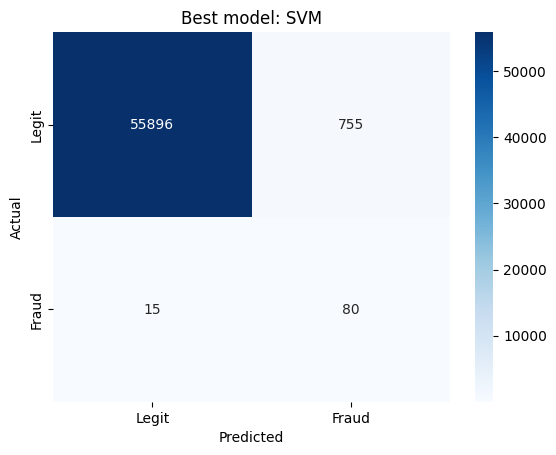

In [12]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
plt.title('Best model: ' + best)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## Conclusion
- Accuracy is high for most models because legit transactions are the vast majority, so it is not used to choose the best model.
- The best model is the one printed above (highest F1). Mention its recall: how many frauds it caught out of the total.
- Precision is low for all models because only the training data was balanced. Many legit transactions get flagged as fraud (false alarms).